<a href="https://colab.research.google.com/github/NihanShaik15/CODEC_INTERNSHIP/blob/main/Customer_Churn_Prediction_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction (Telco)
**Goal:** Predict which customers are likely to stop using the service, and find out why.

**Dataset:** Telco Customer Churn (IBM sample data, Kaggle) - `WA_Fn-UseC_-Telco-Customer-Churn.csv`

**Models:** Logistic Regression, Random Forest, XGBoost

**Metrics:** Accuracy, Precision, Recall, F1, ROC-AUC

> Google Colab me: data loading wale cell ko run karo, "Choose Files" button aayega, wahan se CSV upload karo.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Data Loading and Overview

In [ ]:
# Dataset ko file se upload karke load karte hain (koi API/Kaggle login nahi chahiye)
import io
try:
    # Google Colab: "Choose Files" button aayega, apni CSV select karo
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))
    print("Uploaded file:", file_name)
except ImportError:
    # Laptop / VS Code / Jupyter: CSV same folder me rakho
    df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape:", df.shape)
df.head()

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn.csv
Uploaded file: Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Duplicate rows: 0

Missing values:
 Series([], dtype: int64)


## 2. Data Cleaning
`TotalCharges` has blank strings (new customers with tenure = 0), so it is read as text.
We convert it to numeric and drop those few rows.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges rows:", df["TotalCharges"].isnull().sum())
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

# Drop ID column (no predictive value)
df = df.drop(columns=["customerID"])

# Target: Yes -> 1, No -> 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print("New shape:", df.shape)

Blank TotalCharges rows: 11
New shape: (7032, 20)


## 3. Exploratory Data Analysis (EDA)

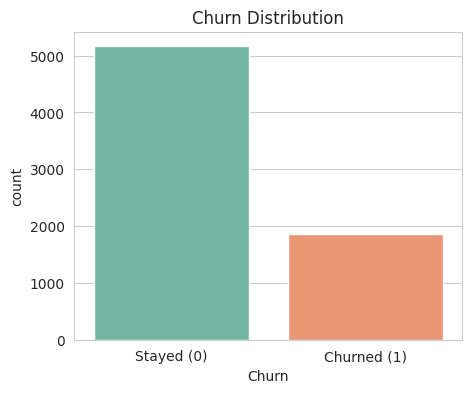

Churn rate: 26.58%


In [ ]:
# Churn distribution
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Churn", data=df, palette="Set2")
ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
plt.title("Churn Distribution")
plt.show()
print(f"Churn rate: {df['Churn'].mean():.2%}")

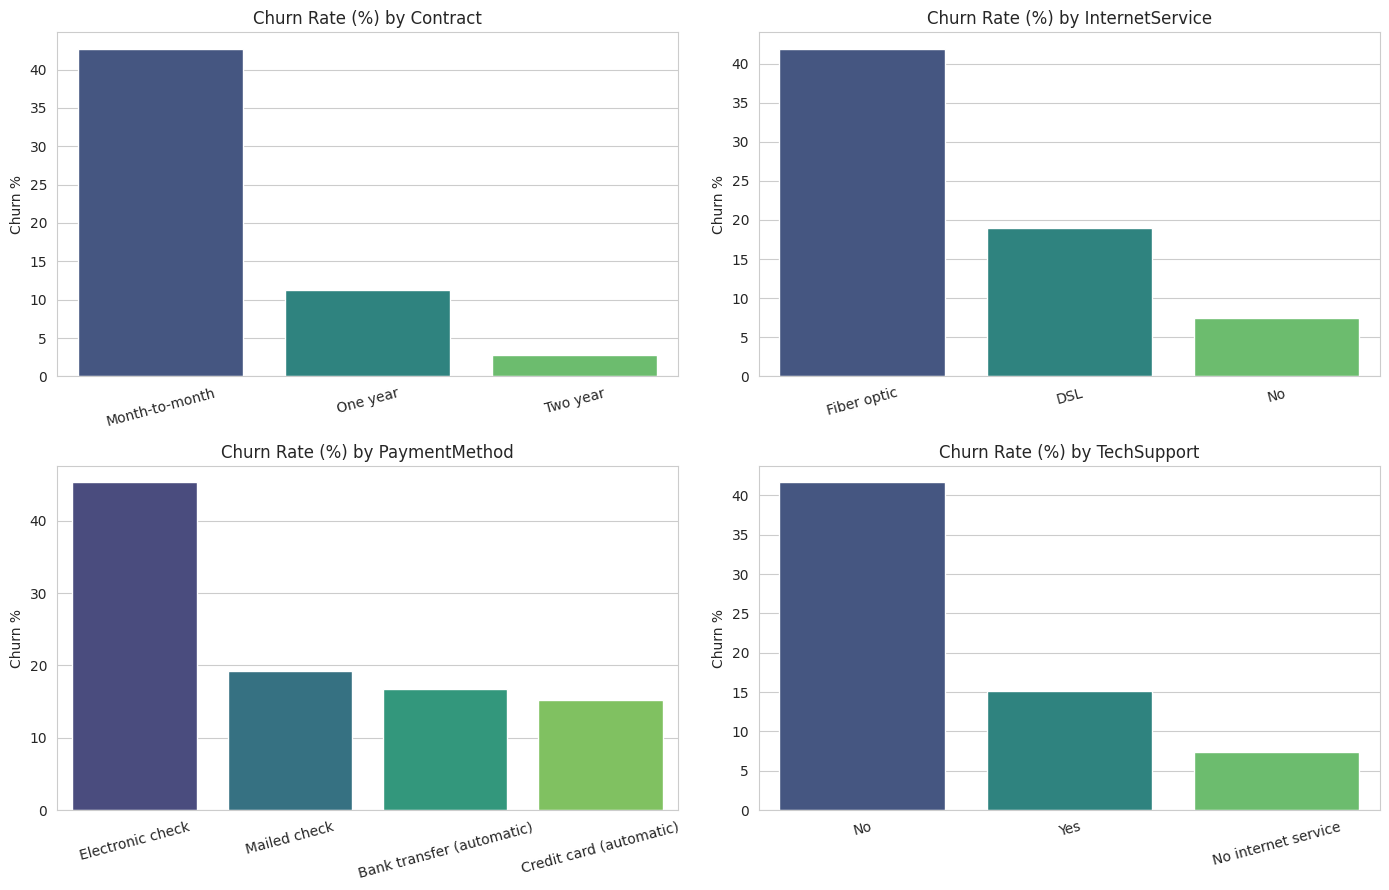

In [ ]:
# Churn vs categorical features
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Churn Rate (%) by {col}")
    ax.set_ylabel("Churn %")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

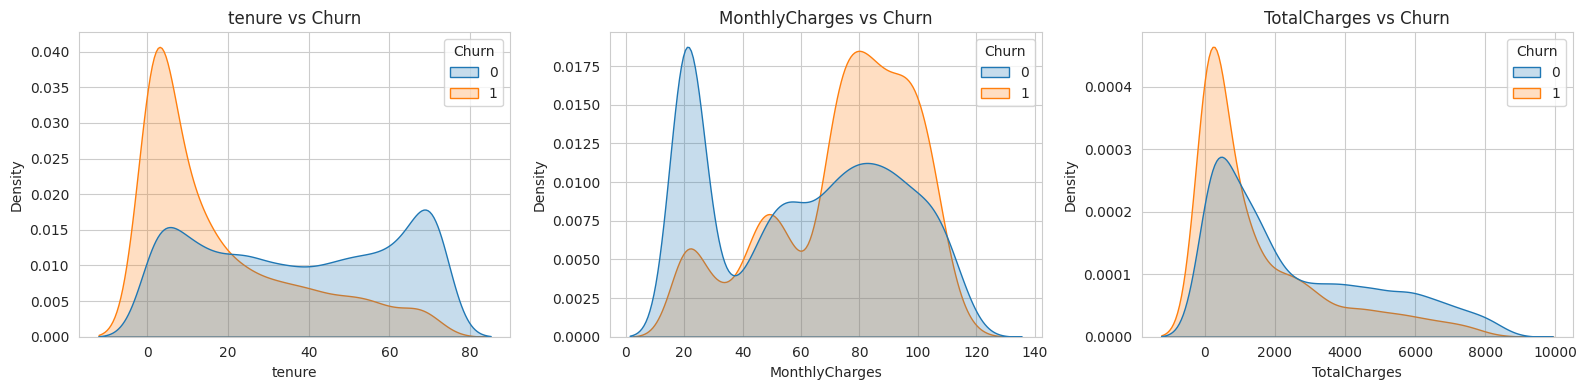

In [ ]:
# Churn vs numerical features
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, common_norm=False, ax=ax)
    ax.set_title(f"{col} vs Churn")
plt.tight_layout()
plt.show()

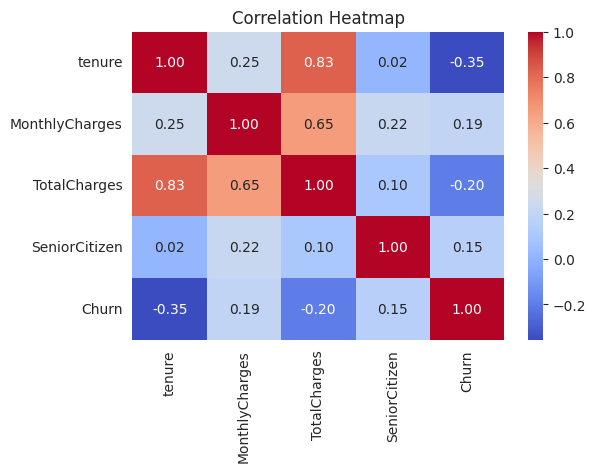

In [ ]:
# Correlation heatmap (numeric + target)
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols + ["SeniorCitizen", "Churn"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### EDA Insights
1. **Month-to-month contracts** churn far more than 1-year or 2-year contracts.
2. **New customers (low tenure)** are the most likely to leave.
3. **Fiber optic** users and customers with **higher monthly charges** churn more.
4. Customers **without Tech Support** churn more, and **electronic check** payers churn more.

(Check the plots above and confirm these on your own run.)

## 4. Preprocessing
- One-hot encode categorical columns
- Stratified 80/20 train-test split
- Scale numeric features (needed for Logistic Regression)
- Class imbalance handled using class weights

In [ ]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Scale only numeric columns, fit on train only (avoids data leakage)
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

# For XGBoost imbalance
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

print("Train:", X_train.shape, " Test:", X_test.shape)
print("scale_pos_weight:", round(scale_pos, 2))

Train: (5625, 30)  Test: (1407, 30)
scale_pos_weight: 2.76


## 5. Model Building

In [ ]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, class_weight="balanced",
                           random_state=RANDOM_STATE),
        True,   # use scaled data
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, max_depth=8,
                               class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1),
        False,
    ),
    "XGBoost": (
        XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                      scale_pos_weight=scale_pos, eval_metric="logloss",
                      random_state=RANDOM_STATE),
        False,
    ),
}

results = []
roc_data = {}
trained = {}

for name, (model, use_scaled) in models.items():
    Xtr = X_train_s if use_scaled else X_train
    Xte = X_test_s if use_scaled else X_test

    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
    roc_data[name] = roc_curve(y_test, proba)
    trained[name] = (model, pred)

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.726,0.490,0.794,0.606,0.835
Random Forest,0.748,0.517,0.778,0.621,0.839
XGBoost,0.729,0.493,0.783,0.605,0.834


## 6. Evaluation
**Why Recall matters for churn:** missing a customer who will actually leave (false negative)
costs more than sending a retention offer to someone who would have stayed (false positive).
So we want high recall, while keeping precision reasonable.

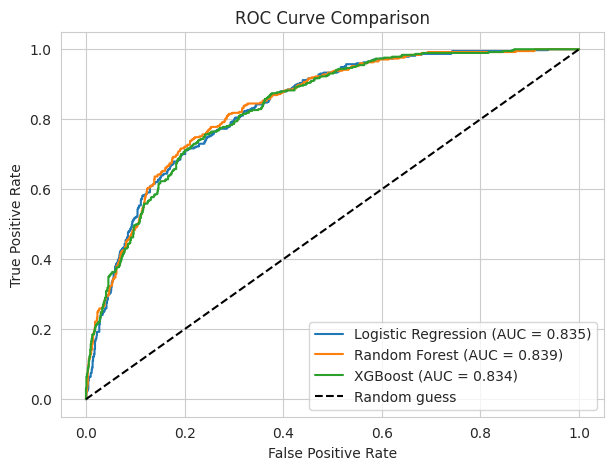

In [ ]:
# ROC curves
plt.figure(figsize=(7, 5))
for name, (fpr, tpr, _) in roc_data.items():
    auc = results_df.loc[name, "ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

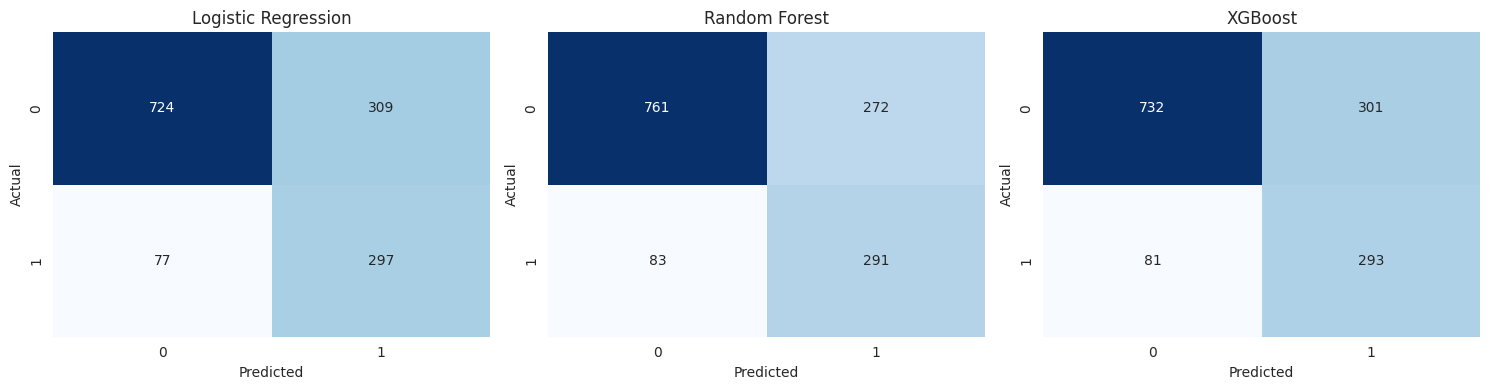

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (_, pred)) in zip(axes, trained.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d",
                cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
best_name = results_df["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best_name)
print(classification_report(y_test, trained[best_name][1],
                            target_names=["Stayed", "Churned"]))

Best model by ROC-AUC: Random Forest
              precision    recall  f1-score   support

      Stayed       0.90      0.74      0.81      1033
     Churned       0.52      0.78      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.75      0.76      1407



## 7. Feature Importance (Random Forest)

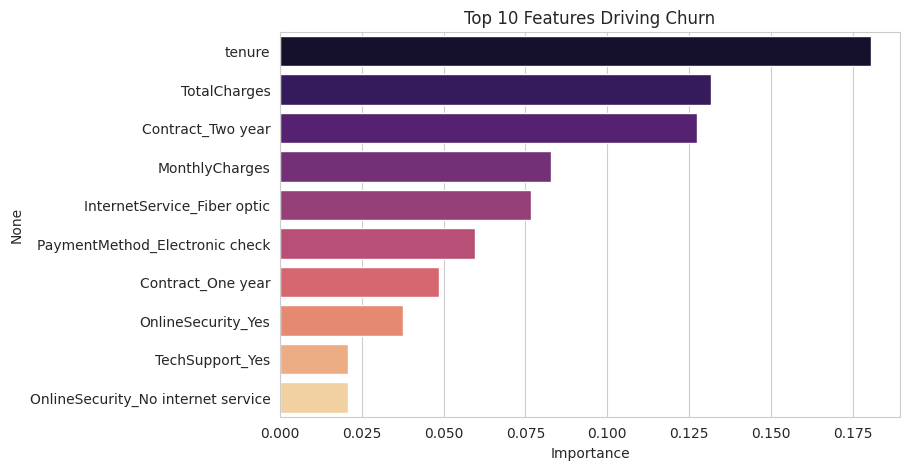

In [ ]:
rf = trained["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=X_train.columns)
top10 = imp.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, palette="magma")
plt.title("Top 10 Features Driving Churn")
plt.xlabel("Importance")
plt.show()

## 8. Business Recommendations
1. **Push long-term contracts:** offer discounts to move month-to-month users to 1/2-year plans.
2. **Focus on early tenure:** run onboarding calls and offers in the first few months.
3. **Bundle Tech Support and Online Security** for at-risk customers.
4. **Review fiber optic pricing and quality:** this group shows higher churn.
5. **Encourage auto-pay** instead of electronic check.

## 9. Conclusion
- Best model: see the table above (compare ROC-AUC and Recall).
- Limitations: only one dataset, no time component, default-ish hyperparameters,
  and the dataset is a sample of a telecom company, so results may not generalize.
- Next steps: hyperparameter tuning (GridSearchCV), SHAP for explainability,
  and a Streamlit app for live predictions.